# Feature engineering: ratios and a school district layer

Week 6. Same data as `03_baseline_model.ipynb` and `04_model_comparison.ipynb` (Dataset A). The training window is fixed at **X = 18 months**: in week 5 every model picked 18, the longest window tried, and a few extra columns are unlikely to change that. Each feature set is compared on the 6 validation months (2025-10 to 2026-03). The test month, 2026-04, is held out and never scored.

Two groups of new features are added to Dataset A:
- **Ratios** of existing columns: bed/bath ratio, living area per bedroom, and log lot size relative to living area. Property age is already in Dataset A (`PropertyAge` = close year − year built), so it is not added again.
- **School districts:** each home's coordinates are spatially joined to the [CA School District Areas 2024-25](https://data.ca.gov/dataset/california-school-district-areas-2024-25) boundaries. This gives the home's elementary district, its high school district, and the share of socioeconomically disadvantaged students in its elementary district.

The district join is in `src/idx_exchange_data_science/features.py`. The ratios lost (section 3), so they are defined in this notebook only. Both are fixed rules that never look at prices, so they run on the whole dataset before the split. Imputation and target encoding of the new columns are still fit on each training window only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import (
    backtest, build_model, feature_importances, fit_window, gain_summary, linear_baseline, median_ape_by, random_forest,
)
from idx_exchange_data_science.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

X = 18  # training window chosen in 04_model_comparison
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
METRICS = ["r2", "mae", "mape", "median_ape", "within_10pct"]
RESULTS_DIR = Path("../results")
RATIO_COLS = ["BedBathRatio", "SqftPerBedroom", "LogLotToLivingArea"]


def add_ratios(df):
    """Ratios of Dataset A columns. NaN where an input is missing (imputed later on train)."""
    return df.assign(
        BedBathRatio=df["BedroomsTotal"] / df["BathroomsTotalInteger"],
        SqftPerBedroom=df["LivingArea"] / df["BedroomsTotal"],
        LogLotToLivingArea=np.log(df["LotSizeSquareFeet"] / df["LivingArea"]),
    )


districts = ft.load_school_districts(ft.DISTRICTS_PATH)
df = da.load_clean(ft.DATASET_A_PATH).pipe(add_ratios).pipe(ft.add_school_districts, districts)
df.shape

(309019, 26)

## 1. The new features
### School district join
The district file has three kinds of district. Unified districts cover K-12. Elementary and High districts overlap each other, so a home in a non-unified area sits in one of each. Each home gets the district that serves its elementary grades and the one that serves its high school grades. In unified areas these are the same district.

In [2]:
districts["DistrictTy"].value_counts()

DistrictTy
Elementary    516
Unified       345
High           76
Name: count, dtype: int64

In [3]:
coverage = pd.DataFrame({
    "distinct values": df[["PostalCode", "City", *ft.DISTRICT_COLS]].nunique(),
    "share missing": df[["PostalCode", "City", *ft.DISTRICT_COLS]].isna().mean(),
})
coverage

,distinct values,share missing
PostalCode,1567,0.0000
City,1098,0.0008
ElementaryDistrict,734,0.0088
HighDistrict,404,0.0095


In [4]:
has_coords = df[["Latitude", "Longitude"]].notna().all(axis=1)
print(f"No coordinates: {(~has_coords).sum():,} homes")
print(f"Coordinates outside every district: {(has_coords & df['ElementaryDistrict'].isna()).sum():,} homes")
print(f"Elementary and high district differ: {(df['ElementaryDistrict'] != df['HighDistrict']).mean():.1%} of homes")

No coordinates: 2,693 homes
Coordinates outside every district: 28 homes
Elementary and high district differ: 25.3% of homes


**Observations**
- **99.1% of homes get a district.** The 2,693 homes without coordinates (0.9%) and the 28 whose coordinates fall outside every boundary are encoded as Unknown.
- **Districts are coarser than ZIP codes:** 734 elementary and 404 high school districts, against 1,567 ZIPs and 1,098 cities. For a quarter of homes the elementary and high school districts differ, so the two columns aren't copies of each other.

### How the new features relate to price
Spearman correlation with ClosePrice (rank-based, so skew doesn't matter), next to two Dataset A features for reference. For the district columns the "correlation" is for the district's median price in the full data, as a rough measure of how much the district alone explains. This is only descriptive. The models use target encodings fit on each training window.

In [5]:
numeric = ["LivingArea", "PropertyAge", *RATIO_COLS, *ft.DISTRICT_NUMERIC_COLS]
spearman = df[numeric].corrwith(df[da.TARGET], method="spearman")
for col in ["PostalCode", "City", *ft.DISTRICT_COLS]:
    group_median = df.groupby(col)[da.TARGET].transform("median")
    spearman[f"{col} (median price)"] = group_median.corr(df[da.TARGET], method="spearman")
spearman.to_frame("spearman_r")

,spearman_r
LivingArea,0.5072
PropertyAge,0.0759
BedBathRatio,-0.2934
SqftPerBedroom,0.3817
LogLotToLivingArea,-0.2355
DistrictSEDPct,-0.4760
PostalCode (median price),0.8870
City (median price),0.8466
ElementaryDistrict (median price),0.8146
HighDistrict (median price),0.8092


**Observations**
- **On their own, districts explain almost as much as ZIP or city** (0.81 vs 0.89 for ZIP), even though they are coarser.
- **`DistrictSEDPct` is the strongest new numeric feature (−0.48),** about as strong as living area. It describes the area's income level, which Dataset A has no direct measure of.
- **The ratios are mostly size restated.** `SqftPerBedroom` (0.38) tracks `LivingArea` (0.51).

## 2. Feature sets and models
Four feature sets, so the two groups can be judged separately and together:

| Feature set | Columns |
|---|---|
| Dataset A | the 17 agreed features (old) |
| + ratios | Dataset A + `BedBathRatio`, `SqftPerBedroom`, `LogLotToLivingArea` |
| + school districts | Dataset A + `ElementaryDistrict`, `HighDistrict` (target-encoded), `DistrictSEDPct` |
| All new features | Dataset A + both groups (new) |

Each set is run with the baseline and the two tree models from week 5, with the same settings. New numeric columns are median-imputed and new categorical columns are target-encoded, the same way as the Dataset A ones. The preprocessor picks each model's columns, so every model is fit on the same data frame.

In [6]:
FEATURE_SETS = {  # (extra numeric, extra categorical)
    "Dataset A": ([], []),
    "+ ratios": (RATIO_COLS, []),
    "+ school districts": (ft.DISTRICT_NUMERIC_COLS, ft.DISTRICT_COLS),
    "All new features": (RATIO_COLS + ft.DISTRICT_NUMERIC_COLS, ft.DISTRICT_COLS),
}


def make_models(numeric, categorical):
    preprocessor = da.make_preprocessor(numeric, categorical)
    return {
        "Linear Regression": linear_baseline(numeric, categorical),
        "Decision Tree": build_model(DecisionTreeRegressor(min_samples_leaf=20, random_state=0), preprocessor),
        "Random Forest": build_model(random_forest(), preprocessor),
    }


models = {name: make_models(numeric, categorical) for name, (numeric, categorical) in FEATURE_SETS.items()}

## 3. Validation
Each model and feature set is trained on the 18 months before each validation month and scored on that month. The first table is the mean over the 6 months. The second is the R² change from Dataset A, month by month, so a gain can be told apart from month-to-month noise.

In [7]:
runs = {name: backtest(models[name], df, EVAL_MONTHS, X) for name in FEATURE_SETS}
results = pd.concat([scores.assign(feature_set=name) for name, (scores, _) in runs.items()], ignore_index=True)

comparison = results.groupby(["model", "feature_set"], sort=False)[METRICS].mean().reset_index()
dataset_a = comparison.query("feature_set == 'Dataset A'").set_index("model")
comparison["r2_vs_dataset_a"] = comparison["r2"] - comparison["model"].map(dataset_a["r2"])
comparison["mae_vs_dataset_a"] = comparison["mae"] - comparison["model"].map(dataset_a["mae"])
comparison

,model,feature_set,r2,mae,mape,median_ape,within_10pct,r2_vs_dataset_a,mae_vs_dataset_a
0,Linear Regression,Dataset A,0.8007,"207,042.7974",0.1609,0.1196,0.4291,0.0000,0.0000
1,Decision Tree,Dataset A,0.8508,"182,382.2943",0.1430,0.0939,0.5232,0.0000,0.0000
2,Random Forest,Dataset A,0.8897,"153,306.3585",0.1210,0.0785,0.5900,0.0000,0.0000
3,Linear Regression,+ ratios,0.7871,"205,792.1444",0.1595,0.1177,0.4348,-0.0137,"-1,250.6530"
4,Decision Tree,+ ratios,0.8492,"183,510.5853",0.1437,0.0944,0.5220,-0.0017,"1,128.2910"
5,Random Forest,+ ratios,0.8864,"156,040.9885",0.1230,0.0794,0.5857,-0.0033,"2,734.6300"
6,Linear Regression,+ school districts,0.8018,"205,336.1209",0.1592,0.1179,0.4352,0.0011,"-1,706.6764"
7,Decision Tree,+ school districts,0.8530,"181,461.5149",0.1422,0.0942,0.5230,0.0021,-920.7795
8,Random Forest,+ school districts,0.8923,"151,207.2719",0.1196,0.0774,0.5969,0.0026,"-2,099.0866"
9,Linear Regression,All new features,0.7879,"204,151.9461",0.1579,0.1160,0.4420,-0.0128,"-2,890.8513"


In [8]:
summary = pd.concat({
    model: gain_summary(group.assign(model=group["feature_set"]), reference="Dataset A")
    for model, group in results.groupby("model", sort=False)
}, names=["model", "feature_set"])
summary

mean gain  std gain  \
model             feature_set                               
Linear Regression + ratios              -0.0137    0.0193   
                  + school districts     0.0011    0.0014   
                  All new features      -0.0128    0.0188   
Decision Tree     + ratios              -0.0017    0.0022   
                  + school districts     0.0021    0.0044   
                  All new features      -0.0000    0.0052   
Random Forest     + ratios              -0.0033    0.0015   
                  + school districts     0.0026    0.0011   
                  All new features       0.0004    0.0018   

                                      months improved (of 6)  
model             feature_set                                 
Linear Regression + ratios                                 1  
                  + school districts                       5  
                  All new features                         2  
Decision Tree     + ratios                                 1  
                  + school districts                       4  
                  All new features                         3  
Random Forest     + ratios                                 0  
                  + school districts                       6  
                  All new features                         3

**Observations**
- **School districts are the only group that helps consistently.** The forest gains 0.003 R² and improves in all 6 months (std 0.001), so the gain is small but real. Linear regression improves in 5 of 6 months, the tree in 4.
- **The ratios make every model worse.** For the forest the loss is small but shows up in every month (−0.003). For linear regression it averages −0.014, mostly from 2026-01 (0.727 vs 0.777) and 2025-10. The ratios have extreme values (up to 8,050 sq ft per bedroom), and a linear model on a log target turns those into very large price errors.
- **With both groups the effects cancel out:** the loss from the ratios offsets the gain from districts.

## 4. Comparison table
Mean validation R², MAE and MAPE for each model and feature set. The Δ columns are the change from the same model on Dataset A.

In [9]:
table = comparison.pivot(index="model", columns="feature_set", values=["r2", "r2_vs_dataset_a", "mae", "mape"])
table = table.reindex(columns=list(FEATURE_SETS), level=1).reindex(["Linear Regression", "Decision Tree", "Random Forest"])
table.style.format({c: "{:.4f}" for c in table.columns if c[0] in ("r2", "r2_vs_dataset_a")}
                   | {c: "${:,.0f}" for c in table.columns if c[0] == "mae"}
                   | {c: "{:.2%}" for c in table.columns if c[0] == "mape"})

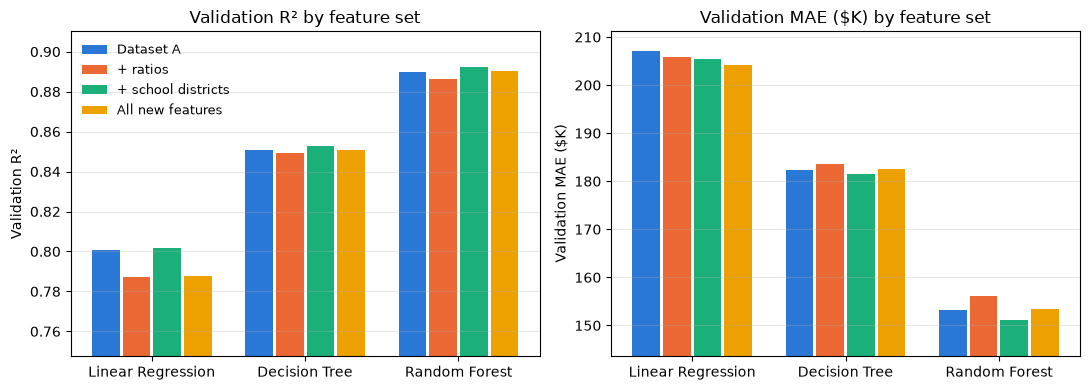

In [10]:
model_order = ["Linear Regression", "Decision Tree", "Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
width = 0.2
for ax, metric, label in [(axes[0], "r2", "Validation R²"), (axes[1], "mae", "Validation MAE ($K)")]:
    values = comparison.pivot(index="model", columns="feature_set", values=metric).loc[model_order, list(FEATURE_SETS)]
    if metric == "mae":
        values = values / 1000
    for i, (color, name) in enumerate(zip(COLORS, FEATURE_SETS)):
        ax.bar(np.arange(3) + (i - 1.5) * width, values[name], width=width - 0.02, color=color, label=name)
    ax.set(xticks=range(3), xticklabels=model_order, ylabel=label, title=f"{label} by feature set")
    ax.set_ylim(values.min().min() * 0.95, values.max().max() * 1.02)
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()

**Observations**
- **The best model is now Random Forest + school districts: validation R² 0.892** (+0.003 over Dataset A), MAE \$151.2K (−\$2.1K), mean % error 12.0%, median % error 7.7%.
- **The gains are small.** ZIP, city and coordinates already cover location well. Districts add a layer between ZIP and county but little new information.
- **Ratios lower R² for all three models,** most for linear regression (−0.014) and then the forest (−0.003, +\$2.7K MAE). Linear regression with all new features has the lowest MAE of the linear models (−\$2.9K) despite its lower R², because its extra errors are concentrated in a few homes.
- **The Decision Tree barely moves** (within ±0.002 for every set). It leans almost entirely on the ZIP encoding, so extra location columns don't change its splits much.

## 5. Where the gain comes from
### Feature importance in the forest
Impurity-based importance from the forest with all new features, fit on the 18 months before 2026-03. As in week 5, read this as a rough ranking only. It favors features with many distinct values, and features that carry the same information (ZIP, city, district) split the credit between them.

In [11]:
importance = pd.DataFrame({
    name: feature_importances(fit_window(models[name]["Random Forest"], df, EVAL_MONTHS[-1], X))
    for name in ["All new features", "Dataset A"]
}).sort_values("All new features", ascending=False)
importance["new"] = importance.index.isin([*RATIO_COLS, *ft.DISTRICT_NUMERIC_COLS, *ft.DISTRICT_COLS])
importance.head(14)

,All new features,Dataset A,new
PostalCode,0.2961,0.3226,False
LivingArea,0.1559,0.1737,False
City,0.1526,0.2159,False
BathroomsTotalInteger,0.0764,0.1020,False
ElementaryDistrict,0.0746,NaN,True
HighDistrict,0.0635,NaN,True
SqftPerBedroom,0.0409,NaN,True
Longitude,0.0167,0.0252,False
LotSizeSquareFeet,0.0164,0.0257,False
DistrictSEDPct,0.0163,NaN,True


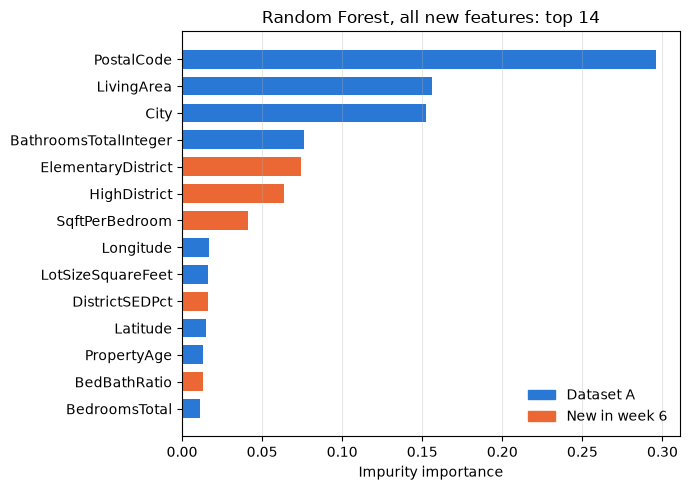

In [12]:
top = importance.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["All new features"], color=np.where(top["new"], COLORS[1], COLORS[0]), height=0.7)
ax.set(xlabel="Impurity importance", title="Random Forest, all new features: top 14")
ax.grid(alpha=0.3, axis="x")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[0]), plt.Rectangle((0, 0), 1, 1, color=COLORS[1])],
          labels=["Dataset A", "New in week 6"], frameon=False, loc="lower right")
plt.tight_layout()

**Observations**
- **The two district encodings rank 5th and 6th,** after ZIP, living area, city and bathrooms. Their importance comes mostly out of ZIP and city (0.32 → 0.30 and 0.22 → 0.15), since all of them describe overlapping areas.
- **`SqftPerBedroom` ranks 7th but doesn't improve predictions.** The trees could already combine living area and bedrooms. Every extra column also means the location features are offered at fewer splits (each split only sees a third of the features). That is a likely reason the ratios cost the forest a little R².

### Error by price decile
Median absolute percentage error over the 6 validation months for the forest, Dataset A vs. the best new feature set. Both are scored on the same rows.

In [13]:
forest_r2 = comparison.query("model == 'Random Forest'").set_index("feature_set")["r2"]
best_set = forest_r2.drop("Dataset A").idxmax()
predictions = pd.DataFrame({name: runs[name][1]["Random Forest"] for name in ["Dataset A", best_set]})
actual = df.loc[predictions.index, da.TARGET]
errors = median_ape_by(predictions, actual, pd.qcut(actual, 10)).assign(change=lambda t: t[best_set] - t["Dataset A"])
print(f"Best new feature set for the forest: {best_set}")
errors.round(2)

Best new feature set for the forest: + school districts


,Dataset A,+ school districts,change
ClosePrice,,,
"(189999.999, 444000.0]",9.1600,8.9900,-0.1800
"(444000.0, 562500.0]",6.1000,6.1400,0.0400
"(562500.0, 675000.0]",5.9300,5.9700,0.0400
"(675000.0, 771735.0]",6.0100,5.9900,-0.0200
"(771735.0, 875000.0]",6.2900,6.0200,-0.2700
"(875000.0, 1025000.0]",7.2200,7.0800,-0.1400
"(1025000.0, 1250000.0]",8.6500,8.4900,-0.1600
"(1250000.0, 1550000.0]",8.9400,8.9100,-0.0400
"(1550000.0, 2200000.0]",10.0900,10.0200,-0.0700


**Observations**
- **The district gain is spread across the price range.** 7 of 10 deciles improve, by up to 0.27 points of median error, including the cheapest and the most expensive. The other three are within 0.04 points, which is noise.

## Summary
Mean validation R² over 2025-10 to 2026-03, X = 18:

| Feature set | Linear Regression | Decision Tree | Random Forest |
|---|---|---|---|
| Dataset A (old) | 0.801 | 0.851 | 0.890 |
| + ratios | 0.787 | 0.849 | 0.886 |
| + school districts | 0.802 | 0.853 | **0.892** |
| All new features | 0.788 | 0.851 | 0.890 |

- **Keep the school district layer, drop the ratios.** Districts improve the forest in every validation month. The ratios hurt every model.
- **New best model: Random Forest + school districts.** Validation R² 0.892, MAE \$151K, mean % error 12.0%.
- **Next steps worth trying:** school-level data joined on district (e.g. test scores), other district attributes from the same file (enrollment, English learner share), and features from raw columns that Dataset A leaves out. If ratios are tried again in a linear model, clip them first.

## 6. Record results

In [14]:
comparison.to_csv(RESULTS_DIR / "feature_comparison.csv", index=False)
results.to_csv(RESULTS_DIR / "feature_comparison_backtest.csv", index=False)
comparison[["model", "feature_set", "r2", "mae", "mape", "median_ape", "r2_vs_dataset_a"]]

,model,feature_set,r2,mae,mape,median_ape,r2_vs_dataset_a
0,Linear Regression,Dataset A,0.8007,"207,042.7974",0.1609,0.1196,0.0000
1,Decision Tree,Dataset A,0.8508,"182,382.2943",0.1430,0.0939,0.0000
2,Random Forest,Dataset A,0.8897,"153,306.3585",0.1210,0.0785,0.0000
3,Linear Regression,+ ratios,0.7871,"205,792.1444",0.1595,0.1177,-0.0137
4,Decision Tree,+ ratios,0.8492,"183,510.5853",0.1437,0.0944,-0.0017
5,Random Forest,+ ratios,0.8864,"156,040.9885",0.1230,0.0794,-0.0033
6,Linear Regression,+ school districts,0.8018,"205,336.1209",0.1592,0.1179,0.0011
7,Decision Tree,+ school districts,0.8530,"181,461.5149",0.1422,0.0942,0.0021
8,Random Forest,+ school districts,0.8923,"151,207.2719",0.1196,0.0774,0.0026
9,Linear Regression,All new features,0.7879,"204,151.9461",0.1579,0.1160,-0.0128
